In [3]:
pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 41.1 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [xarray]o]
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rioxarray as rxr
import xarray as xr
import numpy as np

Adistans_dir = Path(
    "/home/jovyan/BIO597-SpatialBiodiversity/docs/project"
)


*Aulacoseira distans*

In [5]:
Adistans_raw = gpd.read_file(
    Adistans_dir / "Adistans_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Adistans_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Adistans_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Adistans_raw.shape)

(11863, 51)


In [27]:
Adistans_neotoma = gpd.read_file(
    Adistans_dir / "Adistans_Neotoma.csv",
    x_possible_names="long",
    y_possible_names="lat",
).set_crs("EPSG:4326")

Adistans_neotoma['species'] = 'Aulacoseira distans'
Adistans_neotoma['coordinateUncerteintyInMeteres'] = np.nan
Adistans_neotoma['decimalLongitude'] = Adistans_neotoma.long
Adistans_neotoma['decimalLatitude'] = Adistans_neotoma.lat

*Aulacoseria pusilla*

In [8]:
Apusilla_raw = gpd.read_file(
    Adistans_dir / "Apusilla_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Apusilla_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Apusilla_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Apusilla_raw.shape)

(829, 51)


*Aulacoseira perglabra*

In [9]:
Aperglabra_raw = gpd.read_file(
    Adistans_dir / "Aperglabra_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Aperglabra_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Aperglabra_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Aperglabra_raw.shape)

(70, 51)


*Aulacoseira nygaardii*

In [10]:
Anygaardii_raw = gpd.read_file(
    Adistans_dir / "Anygaardii_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Anygaardii_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Anygaardii_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Anygaardii_raw.shape)

(40, 51)


*Aulacoseira alpiega*

In [11]:
Aalpigena_raw = gpd.read_file(
    Adistans_dir / "Aalpigena_GBIF.csv",
    x_possible_names="decimalLongitude",
    y_possible_names="decimalLatitude",
).set_crs("EPSG:4326")

Aalpigena_raw["coordinateUncertaintyInMeters"] = pd.to_numeric(
    Aalpigena_raw["coordinateUncertaintyInMeters"],
    errors="coerce"
)
print(Aalpigena_raw.shape)

(695, 51)


In [28]:
gbif_dfs = [Adistans_raw, Apusilla_raw, Aperglabra_raw, Anygaardii_raw, Aalpigena_raw, Adistans_neotoma]

Aulacoseira_raw = gpd.GeoDataFrame(
    pd.concat(gbif_dfs, ignore_index=True),
    geometry="geometry",
    crs="EPSG:4326"
)

In [29]:

# Read USA boundary
USA_boundary = gpd.read_file(
    Adistans_dir / "cb_2018_us_nation_5m.shp"
)

# Inspect
print(USA_boundary.shape)
print(USA_boundary.crs)
USA_boundary = USA_boundary.dissolve()



(1, 4)
EPSG:4269


In [30]:
Aulacoseira_raw["species"].value_counts(dropna=False).head(20)

species
Aulacoseira distans      11975
Aulacoseira pusilla        829
Aulacoseira alpigena       695
Aulacoseira perglabra       70
Aulacoseira nygaardii       40
Name: count, dtype: int64

In [31]:
Aulacoseira_clean = Aulacoseira_raw.dropna(subset=["decimalLatitude", "decimalLongitude"]).copy()
Aulacoseira_clean.shape

(12953, 60)

In [32]:
Aulacoseira_clean["coordinateUncertaintyInMeters"].value_counts(dropna=False).head(15)

coordinateUncertaintyInMeters
NaN       11156
50.0        481
1000.0      403
10.0        358
5.0         187
100.0       114
70.0         85
99.0         52
0.1          43
7.0          18
1.0           8
250.0         6
2.1           6
3525.0        5
400.0         4
Name: count, dtype: int64

In [33]:
Aulacoseira_clean = Aulacoseira_clean[Aulacoseira_clean["coordinateUncertaintyInMeters"].isna()
    |(Aulacoseira_clean["coordinateUncertaintyInMeters"] <= 1000)
].copy()

Aulacoseira_clean.shape

(12930, 60)

In [34]:
Aulacoseira_clean = Aulacoseira_clean.drop_duplicates(
    subset=["species", "decimalLatitude", "decimalLongitude", "year"]
).copy()

Aulacoseira_clean.shape

(2620, 60)

In [35]:
Aulacoseira_clean.explore()

In [36]:
USA_boundary = USA_boundary.to_crs(Aulacoseira_clean.crs)

# Clip occurrences to USA boundary
Aulacoseira_USA = gpd.clip(
    Aulacoseira_clean,
    USA_boundary
)

print("Original records:", len(Aulacoseira_clean))
print("USA records:", len(Aulacoseira_USA))

Original records: 2620
USA records: 263


In [37]:
Aulacoseira_USA.explore("species")

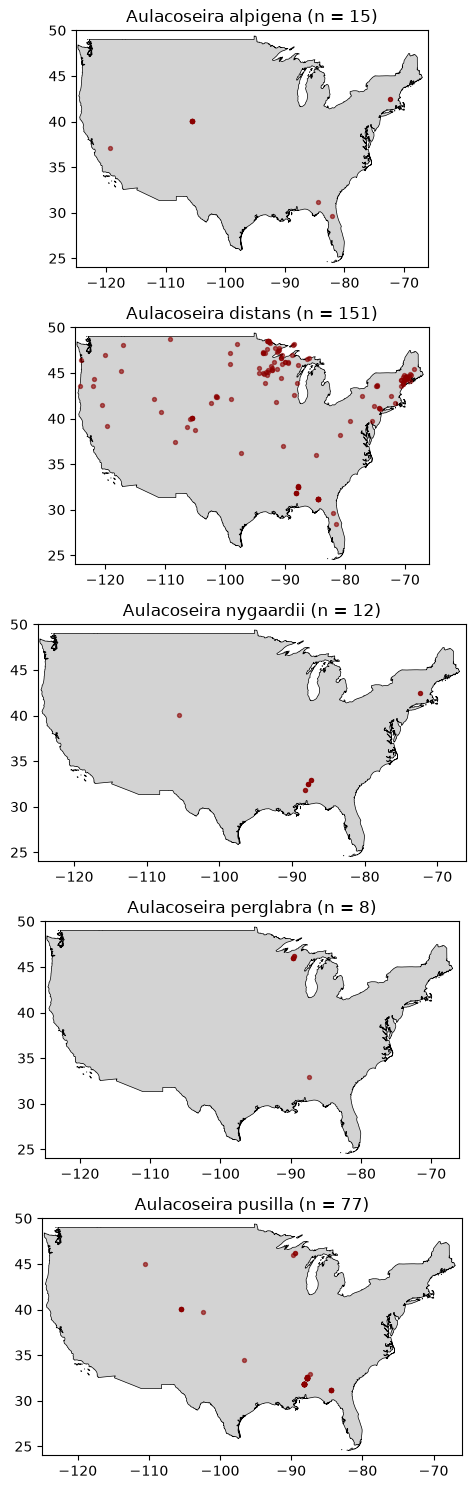

In [38]:

species_list = sorted(Aulacoseira_USA["species"].dropna().unique())

fig, axes = plt.subplots(
    nrows=len(species_list),
    ncols=1,
    figsize=(6, 3 * len(species_list))
)


axes = np.atleast_1d(axes)

for ax, species in zip(axes, species_list):

    USA_boundary.plot(
        ax=ax,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.5
    )

    subset = Aulacoseira_USA[
        Aulacoseira_USA["species"] == species
    ]

    subset.plot(
        ax=ax,
        color="darkred",
        markersize=8,
        alpha=0.6
    )

    ax.set_title(f"{species} (n = {len(subset)})")
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)

plt.tight_layout()
plt.show()

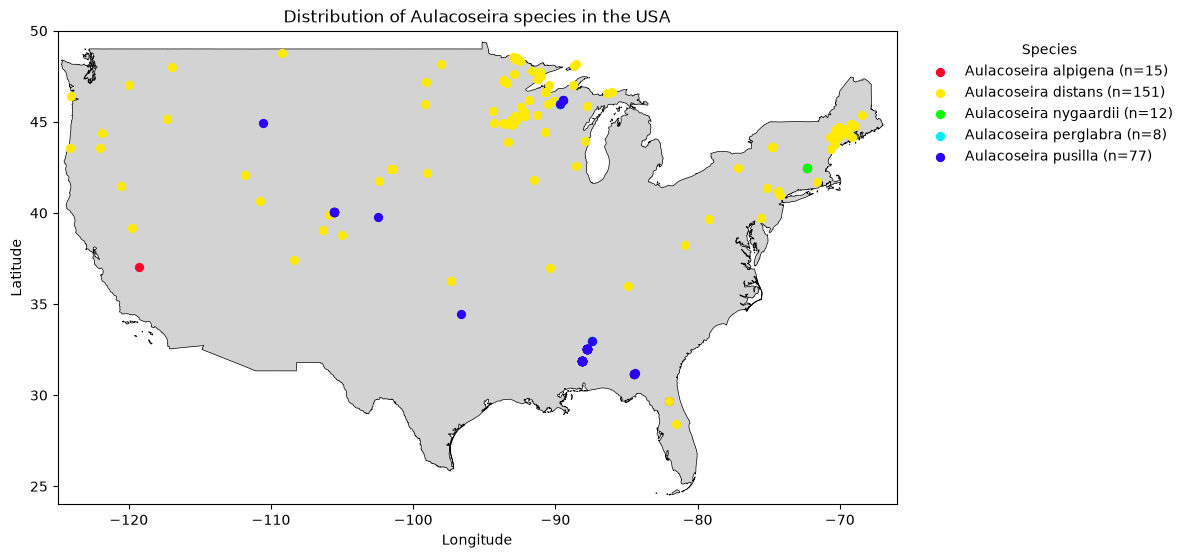

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Species list
species_list = sorted(Aulacoseira_USA["species"].dropna().unique())

# Assign colors
colors = plt.cm.gist_rainbow(
    np.linspace(0, 1, len(species_list), endpoint=False)
)
# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# USA boundary
USA_boundary.to_crs("EPSG:4326").plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.5
)

# Plot each species with a different color
for species, color in zip(species_list, colors):

    subset = Aulacoseira_USA[
        Aulacoseira_USA["species"] == species
    ]

    subset.plot(
        ax=ax,
        color=color,
        markersize=32,
        alpha=1,
        label=f"{species} (n={len(subset)})"
    )

# Map extent: contiguous USA
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)

# Labels
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Distribution of Aulacoseira species in the USA")

# Legend
ax.legend(
    title="Species",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.show()

In [178]:
#Bioclim

In [40]:
bioclim_path = Path("/home/jovyan/shared/bioclim")

bio1 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_1.tif",
    masked=True,
)

bio12 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_12.tif",
    masked=True,
)



In [41]:
bio1_USA = bio1.rio.clip(
    USA_boundary.geometry,
    USA_boundary.crs,
    drop=True,
    from_disk=True,
)

bio1_USA = bio1_USA.squeeze()

bio12_USA = bio12.rio.clip(
    USA_boundary.geometry,
    USA_boundary.crs,
    drop=True,
    from_disk=True,
)

bio12_USA = bio12_USA.squeeze()

In [42]:
print(Aulacoseira_USA.crs)
print(bio1_USA.rio.crs)
print(bio12_USA.rio.crs)

EPSG:4326
EPSG:4326
EPSG:4326


In [43]:
point_x = xr.DataArray(
    Aulacoseira_USA.geometry.x.to_numpy(),
    dims="record",
)

point_y = xr.DataArray(
    Aulacoseira_USA.geometry.y.to_numpy(),
    dims="record",
)

In [44]:
bio1_values = bio1_USA.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

Aulacoseira_USA["bio1_mean_temp_c"] = bio1_values

bio12_values = bio12_USA.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

Aulacoseira_USA["bio12_annual_precip_mm"] = bio12_values
Aulacoseira_USA.head()


,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,...,sitename,lat,long,area,notes,description,elev,coordinateUncerteintyInMeteres,bio1_mean_temp_c,bio12_annual_precip_mm
1545,4901535531,50c9509d-22c7-4a22-a47d-8c48425ef4a7,https://www.inaturalist.org/observations/22164...,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.226334,1229.0
12859,6497943850,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:99332d8a-11ec-4b1b-b080-9dcfc0d36c1f,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira alpigena,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.443167,1296.0
65,6497901454,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:1898bbe2-1c78-42ea-8a49-16a4381c5832,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.443167,1296.0
35,6497952588,d94fc3ee-f21e-4b39-a399-6a6ee9f507ed,uuid:d4434acf-ac9f-4741-a38e-dcfb57b23569,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.109333,1354.0
14,6498022005,ca857858-61fd-4002-a201-c3530f781027,uuid:95c35d54-7be0-4142-9ac9-a86eddef408d,Chromista,Ochrophyta,Bacillariophyceae,Aulacoseirales,Aulacoseiraceae,Aulacoseira,Aulacoseira distans,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.109333,1354.0


In [45]:
Aulacoseira_USA.bio1_mean_temp_c.describe()

count    260.000000
mean      10.344567
std        7.096637
min      -11.716166
25%        4.121958
50%        7.917750
75%       17.773001
max       22.226334
Name: bio1_mean_temp_c, dtype: float64

In [46]:
Aulacoseira_USA.bio12_annual_precip_mm.describe()

count     260.000000
mean     1060.592308
std       380.093165
min       132.000000
25%       744.750000
50%      1126.500000
75%      1400.000000
max      1797.000000
Name: bio12_annual_precip_mm, dtype: float64